In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

plt.style.use("seaborn-v0_8")

STD_DDOF = 0  

pd.set_option("display.precision", 6)
pd.set_option("display.max_rows", 200)


In [2]:
CI_SEED = 11
np.random.seed(CI_SEED)

POPULATION_MU = 105
POPULATION_SIGMA = 20
sample_size = 50

sample = np.random.normal(loc=POPULATION_MU, scale=POPULATION_SIGMA, size=sample_size)
sample[:10], len(sample)


(array([139.98909483,  99.27854006,  95.30869736,  51.93362881,
        104.83430741,  98.60737272,  94.26741276, 111.30805337,
        113.42101433,  83.68794039]),
 50)

In [3]:
sample_mean = float(np.mean(sample))
sample_std = float(np.std(sample, ddof=STD_DDOF))
sample_se = sample_std / math.sqrt(sample_size)

print("seed:", CI_SEED)
print("ddof:", STD_DDOF)
print("sample mean:", sample_mean)
print("sample std:", sample_std)
print("sample standard error (SE):", sample_se)


seed: 11
ddof: 0
sample mean: 103.22364700456181
sample std: 18.064573023858248
sample standard error (SE): 2.5547164168819485


In [4]:
# Exercise 1d

def ci_bounds(mean: float, se: float, z: float) -> tuple[float, float]:
    return (mean - z * se, mean + z * se)

Z_95 = 1.96
Z_90 = 1.64
Z_80 = 1.28

ci_95 = ci_bounds(sample_mean, sample_se, Z_95)
ci_90 = ci_bounds(sample_mean, sample_se, Z_90)
ci_80 = ci_bounds(sample_mean, sample_se, Z_80)

ci_table = pd.DataFrame(
    [
        ("95%", Z_95, ci_95[0], ci_95[1]),
        ("90%", Z_90, ci_90[0], ci_90[1]),
        ("80%", Z_80, ci_80[0], ci_80[1]),
    ],
    columns=["CI level", "Z", "lower", "upper"],
)

ci_table


,CI level,Z,lower,upper
0,95%,1.96,98.216403,108.230891
1,90%,1.64,99.033912,107.413382
2,80%,1.28,99.953610,106.493684


In [7]:
# Exercise 2
n_trials = 1000
Z = Z_95

CI_TRIALS_SEED = 123
rng = np.random.default_rng(CI_TRIALS_SEED)

contains = np.zeros(n_trials, dtype=bool)
ci_lowers = np.empty(n_trials)
ci_uppers = np.empty(n_trials)

for i in range(n_trials):
    s = rng.normal(loc=POPULATION_MU, scale=POPULATION_SIGMA, size=sample_size)
    m = float(np.mean(s))
    sd = float(np.std(s, ddof=STD_DDOF))
    se = sd / math.sqrt(sample_size)
    lo, hi = ci_bounds(m, se, Z)
    ci_lowers[i] = lo
    ci_uppers[i] = hi
    contains[i] = (lo <= POPULATION_MU <= hi)

coverage = float(np.mean(contains))

print("trials seed:", CI_TRIALS_SEED)
print("ddof:", STD_DDOF)
print("n_trials:", n_trials)
print("nominal level:", 0.95)
print("empirical coverage:", coverage)


trials seed: 123
ddof: 0
n_trials: 1000
nominal level: 0.95
empirical coverage: 0.957


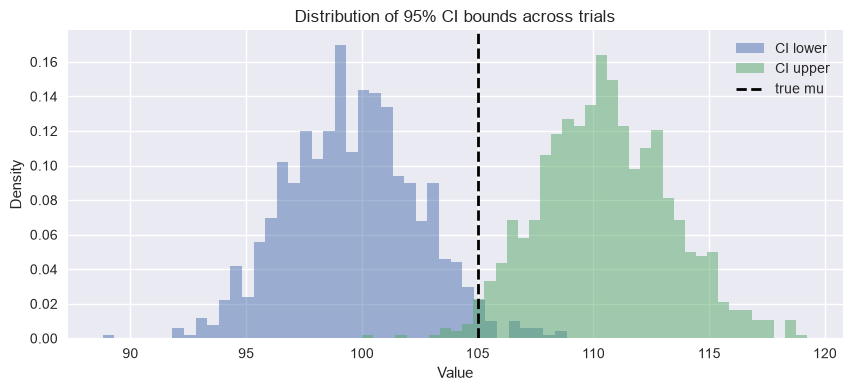

In [9]:
plt.figure(figsize=(10, 4))
plt.hist(ci_lowers, bins=40, density=True, alpha=0.5, label="CI lower")
plt.hist(ci_uppers, bins=40, density=True, alpha=0.5, label="CI upper")
plt.axvline(POPULATION_MU, color="black", linestyle="--", lw=2, label="true mu")
plt.title("Distribution of 95% CI bounds across trials")
plt.xlabel("Value")
plt.ylabel("Density")
plt.legend()
plt.show()


In [10]:
# Exercise 3b

JB_SEED = 2026
np.random.seed(JB_SEED)

N = 1000  # number of trials
M = 1000  # observations per trial
alpha = 0.05

pvalues = np.empty(N)

for i in range(N):
    x = np.random.normal(loc=0.0, scale=1.0, size=M)
    jb_stat, pval = stats.jarque_bera(x)
    pvalues[i] = pval

reject_rate = float(np.mean(pvalues < alpha))

print("seed:", JB_SEED)
print("N trials:", N)
print("M per trial:", M)
print("alpha:", alpha)
print("rejection rate (p < alpha):", reject_rate)


seed: 2026
N trials: 1000
M per trial: 1000
alpha: 0.05
rejection rate (p < alpha): 0.056


In [11]:
pvalues_s = pd.Series(pvalues, name="pvalue")
jb_summary = pvalues_s.describe(percentiles=[0.01, 0.05, 0.1, 0.5, 0.9, 0.95, 0.99])

jb_summary


count    1000.000000
mean        0.497565
std         0.290870
min         0.000027
1%          0.005488
5%          0.044338
10%         0.095996
50%         0.497075
90%         0.896208
95%         0.952352
99%         0.990614
max         0.996752
Name: pvalue, dtype: float64

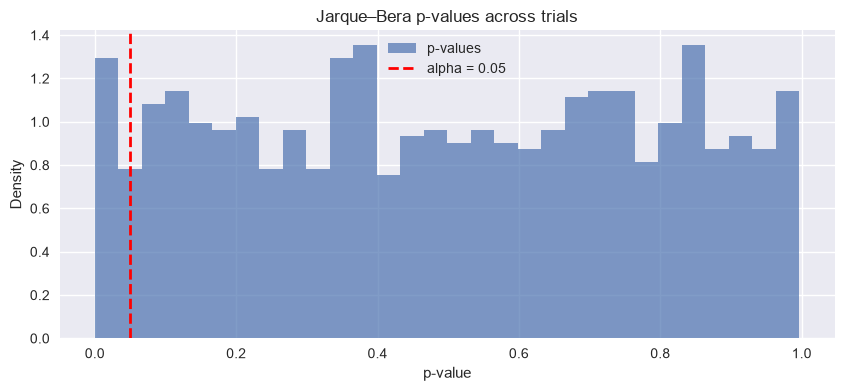

In [12]:
plt.figure(figsize=(10, 4))
plt.hist(pvalues, bins=30, density=True, alpha=0.7, label="p-values")
plt.axvline(alpha, color="red", linestyle="--", lw=2, label="alpha = 0.05")
plt.title("Jarque–Bera p-values across trials")
plt.xlabel("p-value")
plt.ylabel("Density")
plt.legend()
plt.show()


In [13]:
jb_report = pd.DataFrame(
    [
        (JB_SEED, N, M, alpha, reject_rate),
    ],
    columns=["seed", "N_trials", "M_per_trial", "alpha", "reject_rate"],
)

jb_report


,seed,N_trials,M_per_trial,alpha,reject_rate
0,2026,1000,1000,0.05,0.056
